## 1. The task

Every graph in UPFD Gossipcop is the retweet cascade of one news story. The root is the news item. Every other node is a Twitter user who shared it, joined to the account they got it from.

For a cascade $G=(V,E,X)$ we predict one label $y\in\{0,1\}$ for the whole graph, fake or real. This is graph classification.

The model is a Graph Convolutional Network (GCN). We first look at the data, then tune the GCN on the validation split (Milestone 2), and finally run the six analyses of Milestone 3 on the tuned model.

Kaggle already has PyTorch. We install PyTorch Geometric, and Captum for Integrated Gradients. Captum goes in without its pinned dependencies so that it leaves Kaggle's NumPy alone.

In [1]:
!pip install -q torch_geometric
!pip install -q --no-deps captum

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs.

The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`, that were never used for selection. Ablations and robustness use the first five of them, `abl_seeds`.

`n_explain` is the number of test graphs we explain at the end.

In [2]:
epochs, patience = 200, 30
n_trials, search_seeds = 40, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds = final_seeds[:5]
n_explain = 100

## 3. Load the three official splits

PyG ships UPFD with a fixed split: 20% train, 10% validation and 70% test. We keep it, so the GCN and the other two models are compared on exactly the same graphs.

We use the `'content'` node features, a 310-dimensional vector per node.

The data goes to `/tmp` so that Kaggle does not copy 1.4 GB of raw files into the notebook output.

PyG warns on every max-pooling call that an optional package would make it faster, and PGExplainer warns on every training step. We silence just those two messages so they do not bury the results.

In [3]:
import torch
import warnings
from torch_geometric.datasets import UPFD
warnings.filterwarnings('ignore', message='.*can be accelerated via')
warnings.filterwarnings('ignore', message='Converting a tensor with requires_grad')

root = '/tmp/upfd'
raw = {s: UPFD(root, 'gossipcop', 'content', s) for s in ['train', 'val', 'test']}
device = 'cuda' if torch.cuda.is_available() else 'cpu'
for s in raw:
    print(s, "graphs =", len(raw[s]))
print("node features =", raw['train'].num_features, "   device =", device)

train graphs = 1092
val graphs = 546
test graphs = 3826
node features = 310    device = cuda


## 4. One cascade

A graph is stored as node features `x` of shape $|V|\times310$, an edge list `edge_index` of shape $2\times|E|$, and a label `y`.

In [4]:
g = raw['train'][0]
print(g)
print("first edges:", g.edge_index[:, :8].tolist())
print("label:", g.y.item())

Data(x=[76, 310], edge_index=[2, 75], y=[1])
first edges: [[0, 0, 0, 0, 0, 0, 0, 0], [1, 2, 3, 4, 5, 6, 7, 8]]
label: 0


## 5. Check the edge direction

A retweet cascade grows outwards from the news node. If each edge is stored once, as parent $\rightarrow$ child, a GCN passes messages only away from the root, and the root never hears from its users.

We test three things on every graph: is it directed, is it a tree ($|E|=|V|-1$), and is node $0$ the root, i.e. the one node with no incoming edge.

In [5]:
from torch_geometric.utils import degree
graphs = [g for s in raw for g in raw[s]]
print("directed graphs:", sum(g.is_directed() for g in graphs), "of", len(graphs))
print("trees, |E| = |V| - 1:", sum(g.num_edges == g.num_nodes - 1 for g in graphs))
print("node 0 has no parent:", sum(degree(g.edge_index[1], g.num_nodes)[0].item() == 0 for g in graphs))

directed graphs: 5464 of 5464
trees, |E| = |V| - 1: 5464
node 0 has no parent: 5464


## 6. Make the cascades undirected

Every graph is a directed tree hanging from node $0$. `ToUndirected()` adds the reverse of each edge, so information can flow both down and up the cascade, and $|E|$ doubles.

We apply it once and keep the three splits as plain Python lists.

In [6]:
from torch_geometric.transforms import ToUndirected
und = ToUndirected()
train_set, val_set, test_set = [[und(g) for g in raw[s]] for s in raw]
print("all undirected:", all(g.is_undirected() for g in train_set + val_set + test_set))
print("edges in the first graph:", raw['train'][0].num_edges, "->", train_set[0].num_edges)

all undirected: True
edges in the first graph: 75 -> 150


## 7. Class balance and cascade size

If both classes are equally frequent, accuracy is a fair primary metric. We still report macro-F1 and ROC-AUC next to it.

In [7]:
import numpy as np, pandas as pd
y_train, y_val, y_test = [np.array([g.y.item() for g in d]) for d in [train_set, val_set, test_set]]
for s, y in zip(raw, [y_train, y_val, y_test]):
    print(s, "  class 0 =", (y == 0).sum(), "  class 1 =", (y == 1).sum())
counts = pd.DataFrame(dict(y=[g.y.item() for g in graphs], nodes=[g.num_nodes for g in graphs]))
print(counts.groupby('y').nodes.describe().round(1))

train   class 0 = 557   class 1 = 535
val   class 0 = 265   class 1 = 281
test   class 0 = 1910   class 1 = 1916
    count  mean   std  min   25%   50%   75%    max
y                                                  
0  2732.0  76.2  40.6  3.0  48.0  70.0  99.0  199.0
1  2732.0  38.9  41.8  3.0  11.0  22.0  50.0  198.0


## 8. How far does size alone go?

The classes are close to balanced in every split, but their cascades are not the same size: class 0 cascades are much larger than class 1 cascades.

So the number of nodes on its own already carries signal. A logistic regression on $\log|V|$, fitted on the training graphs, tells us how much. Every GCN number below should be read against this one-feature baseline.

In [8]:
from sklearn.linear_model import LogisticRegression
logn = lambda d: np.log([[g.num_nodes] for g in d])
print("test accuracy from log|V| alone:", round(LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test), 4))

test accuracy from log|V| alone: 0.7522


## 9. The two feature blocks

The 310 columns are described as a 300-dimensional text embedding followed by a 10-dimensional user-profile vector. We check this against the `'profile'` and `'spacy'` options of the same dataset by correlating matching columns over all training nodes.

In [9]:
X = torch.cat([g.x for g in train_set])
prof = torch.cat([g.x for g in UPFD(root, 'gossipcop', 'profile', 'train')])
spcy = torch.cat([g.x for g in UPFD(root, 'gossipcop', 'spacy', 'train')])
corr = lambda a, b: ((a - a.mean(0)) * (b - b.mean(0))).mean(0) / (a.std(0, correction=0) * b.std(0, correction=0))
print("last 10 columns vs 'profile', corr per column:", corr(X[:, 300:], prof).numpy().round(3))
print("first 300 columns vs 'spacy', median corr:   ", round(corr(X[:, :300], spcy).median().item(), 3))
print("all features in [", X.min().item(), ",", X.max().item(), "]")

last 10 columns vs 'profile', corr per column: [0.983 0.954 1.    0.999 0.986 0.998 1.    0.989 0.996 0.99 ]
first 300 columns vs 'spacy', median corr:    0.093
all features in [ 0.0 , 1.0000001192092896 ]


The last 10 columns are the profile vector, up to a rescaling. The first 300 columns are a text embedding, but not the same matrix that the `'spacy'` option returns, so from here on we simply call them the **text block** (columns 0 to 299) and the **profile block** (columns 300 to 309).

Every feature already lies in $[0,1]$, so no further scaling is needed.

## 10. The GCN layer

One GCN layer updates every node from itself and its neighbours:

$H^{(l+1)}=\sigma\left(\tilde D^{-1/2}\tilde A\tilde D^{-1/2}H^{(l)}W^{(l)}\right)$

where $\tilde A=A+I$ adds a self-loop to each node and $\tilde D_{ii}=\sum_j\tilde A_{ij}$ is its degree.

For one node this reads $h_i'=\sigma\Big(\sum_{j\in N(i)\cup\{i\}}\frac{1}{\sqrt{\tilde d_i\tilde d_j}}\,W h_j\Big)$, a degree-weighted average over the neighbourhood.

A single layer maps every node's 310 features to a new width.

In [10]:
from torch_geometric.nn import GCNConv
conv = GCNConv(310, 16)
print("one layer:", tuple(train_set[0].x.shape), "->", tuple(conv(train_set[0].x, train_set[0].edge_index).shape))

one layer: (76, 310) -> (76, 16)


## 11. From nodes to one graph vector

After $L$ layers each node has seen its $L$-hop neighbourhood. PyG's `GCN` stacks $L$ such layers with ReLU, dropout and optional batch norm in between.

A readout then pools the node embeddings into one vector per graph, $h_G=\text{READOUT}\{h_v^{(L)}:v\in V\}$, with the mean, the max or the sum.

The UPFD paper adds one more input: the raw features of the news node, $x_{\text{root}}$. With `root=True` we append $\text{ReLU}(W_r x_{\text{root}})$ to $h_G$. Node $0$ is the root of every graph, so in a mini-batch the root of each graph is its first node.

An MLP maps the graph vector to two logits. Training settings stored in the same dictionary, such as the learning rate, are ignored by the model.

In [11]:
import torch.nn.functional as F
from torch_geometric.nn import GCN, MLP, global_mean_pool, global_max_pool, global_add_pool

pools = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=2, dropout=0.5, pool='mean', root=False, norm=None, **_):
        super().__init__()
        self.gnn = GCN(310, hidden, layers, dropout=dropout, norm=norm)
        self.pool = pools[pool]
        self.news = torch.nn.Linear(310, hidden) if root else None
        self.head = MLP([2 * hidden if root else hidden, hidden, 2], dropout=dropout, norm=None)

    def embed(self, x, edge_index, batch=None):
        if batch is None:
            batch = x.new_zeros(x.size(0), dtype=torch.long)
        h = self.pool(self.gnn(x, edge_index).relu(), batch)
        if self.news is not None:
            n = torch.bincount(batch)
            h = torch.cat([h, self.news(x[n.cumsum(0) - n]).relu()], dim=1)
        return h

    def forward(self, x, edge_index, batch=None):
        return self.head(self.embed(x, edge_index, batch))

## 12. Train with early stopping on validation accuracy

We minimise cross-entropy with Adam on mini-batches of training graphs. After every epoch we measure validation accuracy, keep the best weights so far, and stop once it has not improved for `patience` epochs. The test split is never used here.

The validation and test graphs never change, so we batch them once and keep them on the GPU. `predict` returns $P(y=1\mid G)$ for every graph.

In [12]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=512):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

@torch.no_grad()
def predict(model, bs):
    model.eval()
    return torch.cat([model(b.x, b.edge_index, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=c['batch'], shuffle=True)
    best, wait = -1, 0
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.batch), b.y).backward()
            opt.step()
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

val_b, test_b = batches(val_set), batches(test_set)

## 13. A plain GCN baseline

Before tuning anything we train a textbook configuration: two GCN layers of width 64, mean readout, no root features, and the dropout ($0.5$), learning rate ($0.01$) and weight decay ($5\cdot10^{-4}$) of Kipf and Welling's original GCN.

It is trained on the ten final seeds and we report test metrics as mean and standard deviation.

In [13]:
baseline = dict(hidden=64, layers=2, dropout=0.5, pool='mean', root=False, norm=None, lr=0.01, wd=5e-4, batch=128)
base = pd.DataFrame([scores(y_test, predict(fit(baseline, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.9473  0.9473  0.9810
std   0.0051  0.0051  0.0016


## 14. The search space

We tune nine hyperparameters. Depth and width set the capacity; dropout and weight decay regularise; the readout and the root features decide how the graph vector is formed; batch norm, learning rate and batch size affect the optimisation.

The full grid is too large to run, so we draw `n_trials` configurations uniformly at random. Random search covers every single hyperparameter well with few trials (Bergstra and Bengio, 2012).

In [14]:
import random
space = dict(hidden=[32, 64, 128, 256], layers=[1, 2, 3, 4], dropout=[0.0, 0.2, 0.5],
             pool=['mean', 'max', 'add'], root=[False, True], norm=[None, 'batch_norm'],
             lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4, 1e-3], batch=[64, 128])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")

40 of 13824 configurations


## 15. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy.

Averaging over seeds matters: the validation split has only 546 graphs, so a single graph moves accuracy by $0.18\%$.

In [15]:
import time
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.9585 ± 0.0031  (22s)  {'hidden': 256, 'layers': 4, 'dropout': 0.0, 'pool': 'max', 'root': True, 'norm': 'batch_norm', 'lr': 0.003, 'wd': 0.001, 'batch': 128}
 1  val = 0.9646 ± 0.0023  (24s)  {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'pool': 'mean', 'root': False, 'norm': 'batch_norm', 'lr': 0.01, 'wd': 1e-05, 'batch': 128}
 2  val = 0.9652 ± 0.0000  (29s)  {'hidden': 32, 'layers': 1, 'dropout': 0.5, 'pool': 'max', 'root': True, 'norm': None, 'lr': 0.003, 'wd': 0.001, 'batch': 128}
 3  val = 0.9542 ± 0.0015  (61s)  {'hidden': 64, 'layers': 4, 'dropout': 0.2, 'pool': 'add', 'root': True, 'norm': None, 'lr': 0.01, 'wd': 0.0, 'batch': 64}
 4  val = 0.9609 ± 0.0023  (40s)  {'hidden': 256, 'layers': 1, 'dropout': 0.5, 'pool': 'max', 'root': True, 'norm': None, 'lr': 0.01, 'wd': 0.0001, 'batch': 64}
 5  val = 0.9591 ± 0.0017  (31s)  {'hidden': 64, 'layers': 2, 'dropout': 0.0, 'pool': 'mean', 'root': True, 'norm': None, 'lr': 0.001, 'wd': 0.0001, 'batch': 128}
 6  val = 0.9713 ±

## 16. The best configuration

We rank by mean validation accuracy and keep the top configuration.

Each panel below shows every trial's validation accuracy against one hyperparameter. A panel where the values separate cleanly marks a choice that matters; a flat one marks a choice that does not.

    hidden  layers  dropout  pool   root        norm     lr     wd  batch     val  val_std
25      32       4      0.2   max   True        None  0.003  0.000     64  0.9731   0.0009
32     128       3      0.2   add  False  batch_norm  0.010  0.000     64  0.9719   0.0023
6       32       3      0.5   max  False  batch_norm  0.010  0.000    128  0.9713   0.0023
18      32       2      0.0   max   True        None  0.010  0.001     64  0.9689   0.0040
28     256       4      0.5  mean  False  batch_norm  0.003  0.000    128  0.9683   0.0017
30     128       3      0.2   add  False  batch_norm  0.010  0.001    128  0.9676   0.0035
21      64       4      0.2   add   True  batch_norm  0.010  0.000    128  0.9676   0.0023
10     256       3      0.2   max   True        None  0.003  0.000    128  0.9664   0.0023
17      32       4      0.0   max   True  batch_norm  0.010  0.000     64  0.9664   0.0017
23      64       2      0.5   max   True  batch_norm  0.001  0.001    128  0.9658   0.0009

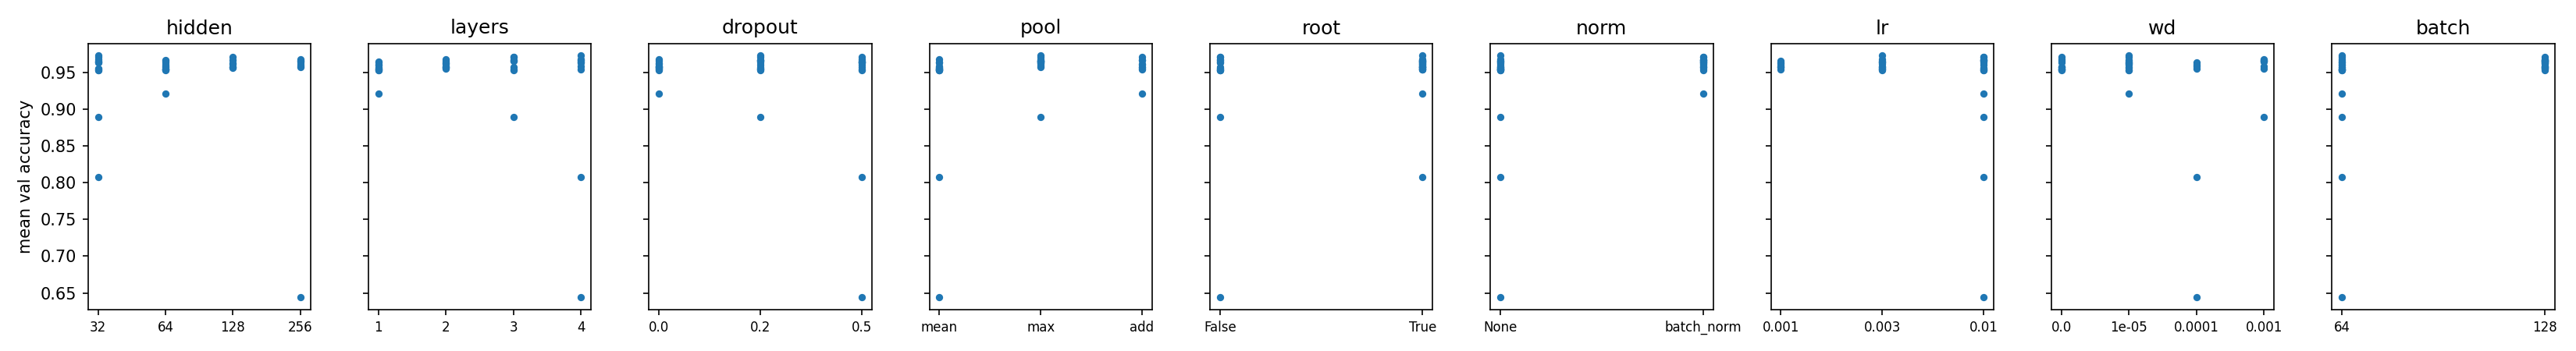

In [16]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = trials[search.index[0]]
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(22, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('gcn_search.png', dpi=150); plt.show()

## 17. Test the tuned GCN on ten fresh seeds

The search used seeds 0 to 2. We retrain the chosen configuration on ten new seeds and score each run once on the 3,826 test graphs. The spread over seeds shows how much of any difference is noise.

In [17]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'baseline': base.mean(), 'baseline std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

     baseline  baseline std   tuned  tuned std
acc    0.9473        0.0051  0.9702     0.0029
f1     0.9473        0.0051  0.9701     0.0029
auc    0.9810        0.0016  0.9876     0.0012


## 18. The model we analyse

The analyses that need a single model use the run with the highest validation accuracy among the ten. Picking the highest test accuracy instead would be peeking at the test set.

Its confusion matrix shows whether the errors fall mostly on one class.

seed 102   val acc = 0.9744   test: {'acc': 0.9723, 'f1': 0.9723, 'auc': np.float64(0.9886)}


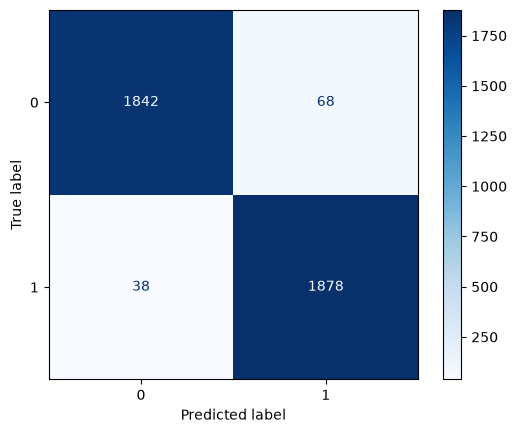

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(v, 4) for m, v in scores(y_test, p_best).items()})
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5)).plot(cmap='Blues'); plt.show()

## 19. Ablation: which parts of the input does the GCN need?

An ablation removes one ingredient and retrains with the same tuned hyperparameters on the five seeds in `abl_seeds`. Train, validation and test graphs are changed in the same way.

- **No edges ($\tilde A=I$).** Each node sees only itself, so the GCN becomes a per-node MLP followed by the readout.
- **Constant features.** Every $x_v$ becomes a vector of ones, so only the shape of the cascade is left.
- **Random tree.** The users stay but are re-attached at random: node $i$ gets a parent drawn uniformly from $0,\ldots,i-1$. The size is kept; who-retweeted-whom is lost.
- **Text only / profile only.** One of the two feature blocks is set to zero.
- **News node only.** Every user is deleted and only the root remains. This asks whether the cascade adds anything to the article itself.
- **Directed edges.** We skip `ToUndirected()`, so messages flow only from parent to child.

In [19]:
from torch_geometric.utils import to_undirected

def no_edges(g): g.edge_index = g.edge_index[:, :0]; return g
def ones(g):     g.x = torch.ones_like(g.x); return g
def text(g):     g.x[:, 300:] = 0; return g
def profile(g):  g.x[:, :300] = 0; return g
def news(g):     g.x, g.edge_index = g.x[:1], g.edge_index[:, :0]; return g
def rand_tree(g):
    child = torch.arange(1, g.num_nodes)
    g.edge_index = to_undirected(torch.stack([(torch.rand(len(child)) * child).long(), child]))
    return g

def variant(f):
    return [f(g.clone()) for g in train_set], batches([f(g.clone()) for g in val_set]), batches([f(g.clone()) for g in test_set])

def run(c, tr, va, te):
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in abl_seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

torch.manual_seed(0)
abl = {'tuned GCN': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', ones), ('random tree', rand_tree),
                ('text features only', text), ('profile features only', profile), ('news node only', news)]:
    abl[name] = run(best, *variant(f))
abl['directed edges'] = run(best, list(raw['train']), batches(list(raw['val'])), batches(list(raw['test'])))
print(table(abl))

                          acc      f1     auc  acc std   Δ acc
tuned GCN              0.9686  0.9686  0.9868   0.0032  0.0000
no edges (A = I)       0.9658  0.9658  0.9856   0.0046 -0.0028
constant features      0.7440  0.7360  0.8173   0.0011 -0.2246
random tree            0.9632  0.9632  0.9852   0.0023 -0.0054
text features only     0.9571  0.9571  0.9796   0.0120 -0.0115
profile features only  0.9153  0.9152  0.9698   0.0124 -0.0533
news node only         0.9476  0.9476  0.9828   0.0048 -0.0210
directed edges         0.9467  0.9467  0.9815   0.0087 -0.0219


## 20. Ablation: readout and root features

Now the data stays fixed and we change one architectural choice of the tuned configuration at a time: the other two readouts, and the root-feature shortcut switched the other way.

In [20]:
arch = {'tuned GCN': tuned.iloc[:len(abl_seeds)]}
for p in space['pool']:
    if p != best['pool']:
        arch[f'{p} readout'] = run(dict(best, pool=p), train_set, val_b, test_b)
arch[f"root features = {not best['root']}"] = run(dict(best, root=not best['root']), train_set, val_b, test_b)
print(table(arch))

                          acc      f1     auc  acc std   Δ acc
tuned GCN              0.9686  0.9686  0.9868   0.0032  0.0000
mean readout           0.9570  0.9570  0.9824   0.0046 -0.0116
add readout            0.9484  0.9483  0.9803   0.0041 -0.0203
root features = False  0.9463  0.9462  0.9745   0.0514 -0.0224


## 21. Ablation: depth and over-smoothing

Each GCN layer averages a node with its neighbours. Repeated averaging pulls the embeddings of a connected graph towards the same vector, which is called over-smoothing, so accuracy should eventually fall as layers are added.

We train 1, 2, 4 and 8 layers. We do it with and without the root shortcut, because the shortcut lets the classifier read the news features directly and bypass the GCN.

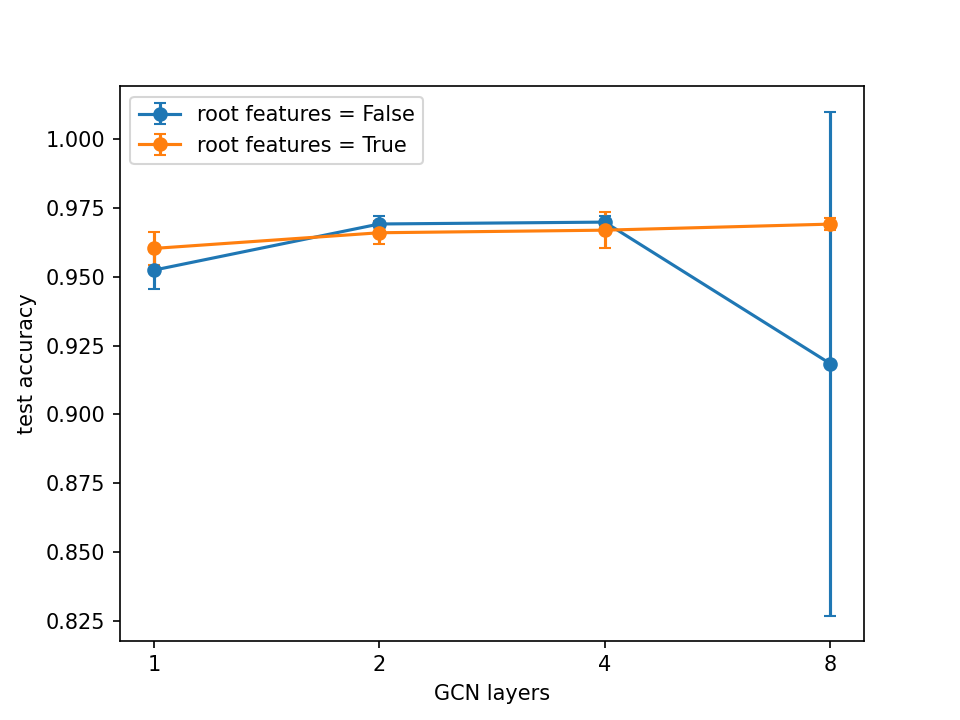

In [21]:
Ls = [1, 2, 4, 8]
depth = {(r, L): run(dict(best, root=r, layers=L), train_set, val_b, test_b) for r in [False, True] for L in Ls}
for r in [False, True]:
    plt.errorbar(Ls, [depth[r, L].acc.mean() for L in Ls], [depth[r, L].acc.std() for L in Ls], marker='o', capsize=3, label=f'root features = {r}')
plt.xscale('log', base=2); plt.xticks(Ls, Ls)
plt.xlabel("GCN layers"); plt.ylabel("test accuracy"); plt.legend()
plt.savefig('gcn_depth.png', dpi=150); plt.show()

## 22. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per graph. t-SNE maps these vectors to 2D while keeping near neighbours near.

On the left is the input itself, the mean of each graph's raw node features. On the right is the tuned GCN's embedding. Colour is the true class, and crosses are graphs the model gets wrong.

The silhouette score, computed in the original space and not in 2D, measures class separation on a scale from $-1$ to $1$.

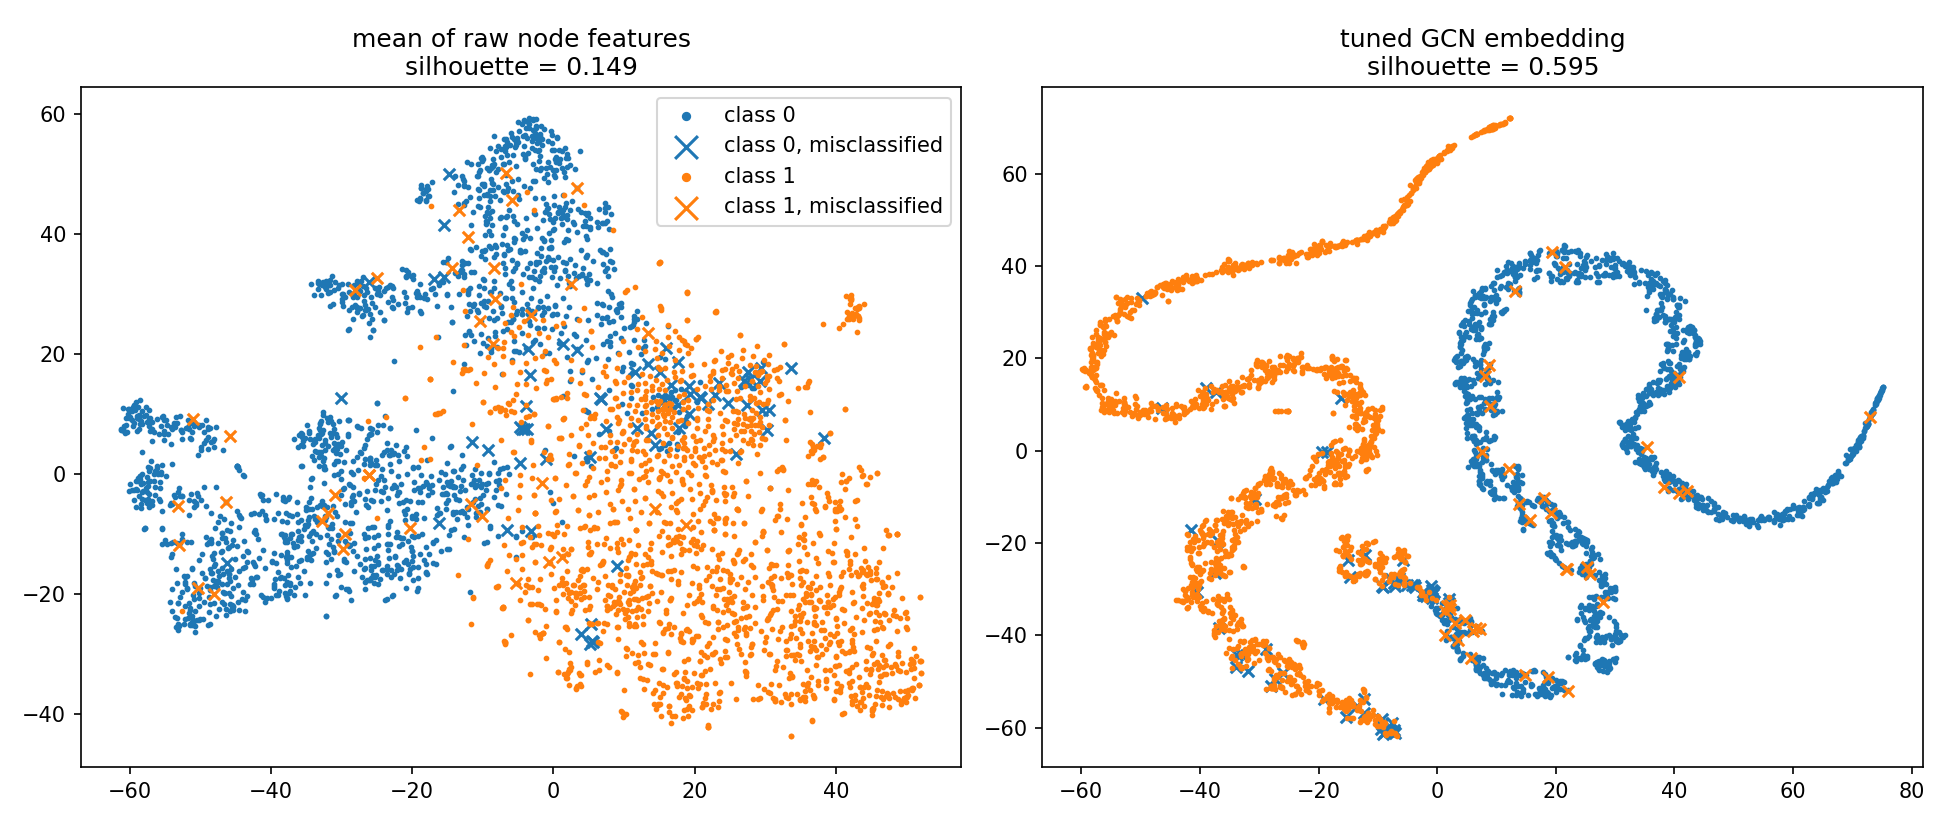

In [22]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw node features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GCN embedding': embed_all(model, test_b)}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=3, c=col, label=f'class {c}')
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'class {c}, misclassified')
    a.set_title(f"{name}\nsilhouette = {silhouette_score(E, y_test):.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('gcn_tsne.png', dpi=150); plt.show()

## 23. Efficiency: the cost of one model

For the tuned GCN we measure

- the number of trainable parameters,
- the wall-clock time of one training epoch, averaged over ten epochs after one warm-up epoch,
- the peak GPU memory during training, above what the stored validation and test batches already take,
- the time to score all 3,826 test graphs, and the median latency of one graph at batch size 1.

On the GPU, `synchronize()` makes the timer wait until the kernels have finished.

In [23]:
sync = torch.cuda.synchronize if device == 'cuda' else (lambda: None)
one_b = batches(test_set[:200], size=1)

def cost(c, n=10):
    seed_everything(0)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(train_set, batch_size=c['batch'], shuffle=True)
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
    times = []
    for epoch in range(n + 1):
        sync(); t = time.time()
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.batch), b.y).backward()
            opt.step()
        sync(); times.append(time.time() - t)
    peak = (torch.cuda.max_memory_allocated() - m0) / 2**20 if device == 'cuda' else float('nan')
    sync(); t = time.time(); predict(model, test_b); sync(); full = time.time() - t
    lat = []
    for b in one_b:
        sync(); t = time.time(); predict(model, [b]); sync(); lat.append(time.time() - t)
    return dict(params=sum(p.numel() for p in model.parameters()), epoch_s=np.mean(times[1:]),
                peak_train_mb=peak, test_set_s=full, one_graph_ms=1000 * np.median(lat))

eff = cost(best)
for k, v in eff.items():
    print(f"{k:14s} {v:.4g}")

params         2.522e+04
epoch_s        0.2191
peak_train_mb  15.93
test_set_s     0.04638
one_graph_ms   3.977


## 24. Accuracy against model size

Width drives the parameter count. We vary the hidden size of the tuned configuration from 16 to 512, train three seeds at each width, and plot test accuracy against parameters, next to the time per epoch.

   hidden     acc  acc_std   params  epoch_s  peak_train_mb  test_set_s  one_graph_ms
0      16  0.9699   0.0014    11330   0.2100        11.5894      0.0386        3.9902
1      32  0.9709   0.0009    25218   0.2080        15.9307      0.0451        4.2723
2      64  0.9696   0.0012    60674   0.2143        27.5762      0.0572        3.9721
3     128  0.9585   0.0143   162306   0.2154        44.7310      0.0824        4.0699
4     256  0.9617   0.0121   488450   0.2151        77.9595      0.1357        4.1448
5     512  0.9679   0.0023  1632258   0.2833       153.5527      0.2998        4.1425


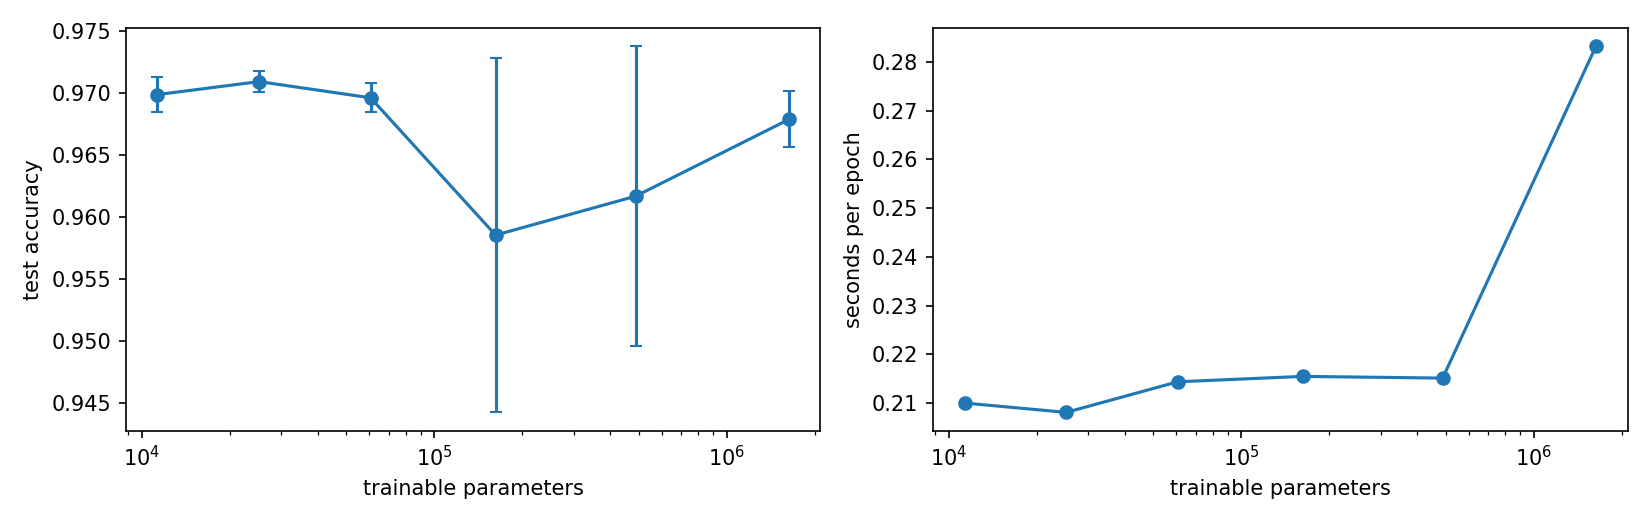

In [24]:
size_rows = []
for h in [16, 32, 64, 128, 256, 512]:
    c = dict(best, hidden=h)
    acc = [scores(y_test, predict(fit(c, s)[0], test_b))['acc'] for s in abl_seeds[:3]]
    size_rows.append(dict(hidden=h, acc=np.mean(acc), acc_std=np.std(acc), **cost(c)))
sizes = pd.DataFrame(size_rows)
print(sizes.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(sizes.params, sizes.acc, sizes.acc_std, marker='o', capsize=3)
ax[1].plot(sizes.params, sizes.epoch_s, marker='o')
for a, lab in zip(ax, ["test accuracy", "seconds per epoch"]):
    a.set_xscale('log'); a.set_xlabel("trainable parameters"); a.set_ylabel(lab)
plt.tight_layout(); plt.savefig('gcn_size.png', dpi=150); plt.show()

## 25. Robustness: missing edges and noisy features

We perturb only the test graphs and re-score the ten tuned runs, which were trained on clean data.

- **Edge removal.** Each undirected edge is removed with probability $p$, for $p$ from $0$ to $0.5$. Both directions go together.
- **Feature noise.** We add $\sigma\, s_j\,\varepsilon$ to feature $j$ of every node, where $s_j$ is the standard deviation of feature $j$ over the training nodes and $\varepsilon\sim\mathcal N(0,1)$.

In [25]:
from torch_geometric.utils import dropout_edge
sd = X.std(0).to(device)

def perturb(bs, p=0.0, sigma=0.0):
    out = []
    for b in bs:
        b = b.clone()
        b.edge_index = dropout_edge(b.edge_index, p=p, force_undirected=True)[0]
        b.x = b.x + sigma * sd * torch.randn_like(b.x)
        out.append(b)
    return out

torch.manual_seed(0)
drop = {p: [scores(y_test, predict(m, perturb(test_b, p=p)))['acc'] for m, _ in runs] for p in [0, .1, .2, .3, .4, .5]}
noise = {s: [scores(y_test, predict(m, perturb(test_b, sigma=s)))['acc'] for m, _ in runs] for s in [0, .1, .25, .5, 1, 2]}

## 26. Robustness: scarce labels

The other kind of imperfect data is having few labels. We train on a stratified fraction of the 1,092 training graphs, from 5% (54 graphs) up to all of them, and keep the full validation split for early stopping.

In [26]:
from sklearn.model_selection import train_test_split
labels = {}
for f in [.05, .1, .25, .5, 1.0]:
    accs = []
    for s in abl_seeds:
        idx = np.arange(len(train_set)) if f == 1 else train_test_split(np.arange(len(train_set)), train_size=f, stratify=y_train, random_state=s)[0]
        accs.append(scores(y_test, predict(fit(best, s, [train_set[i] for i in idx])[0], test_b))['acc'])
    labels[f] = accs

## 27. Robustness curves

Each point is the mean test accuracy over runs; the error bar is one standard deviation.

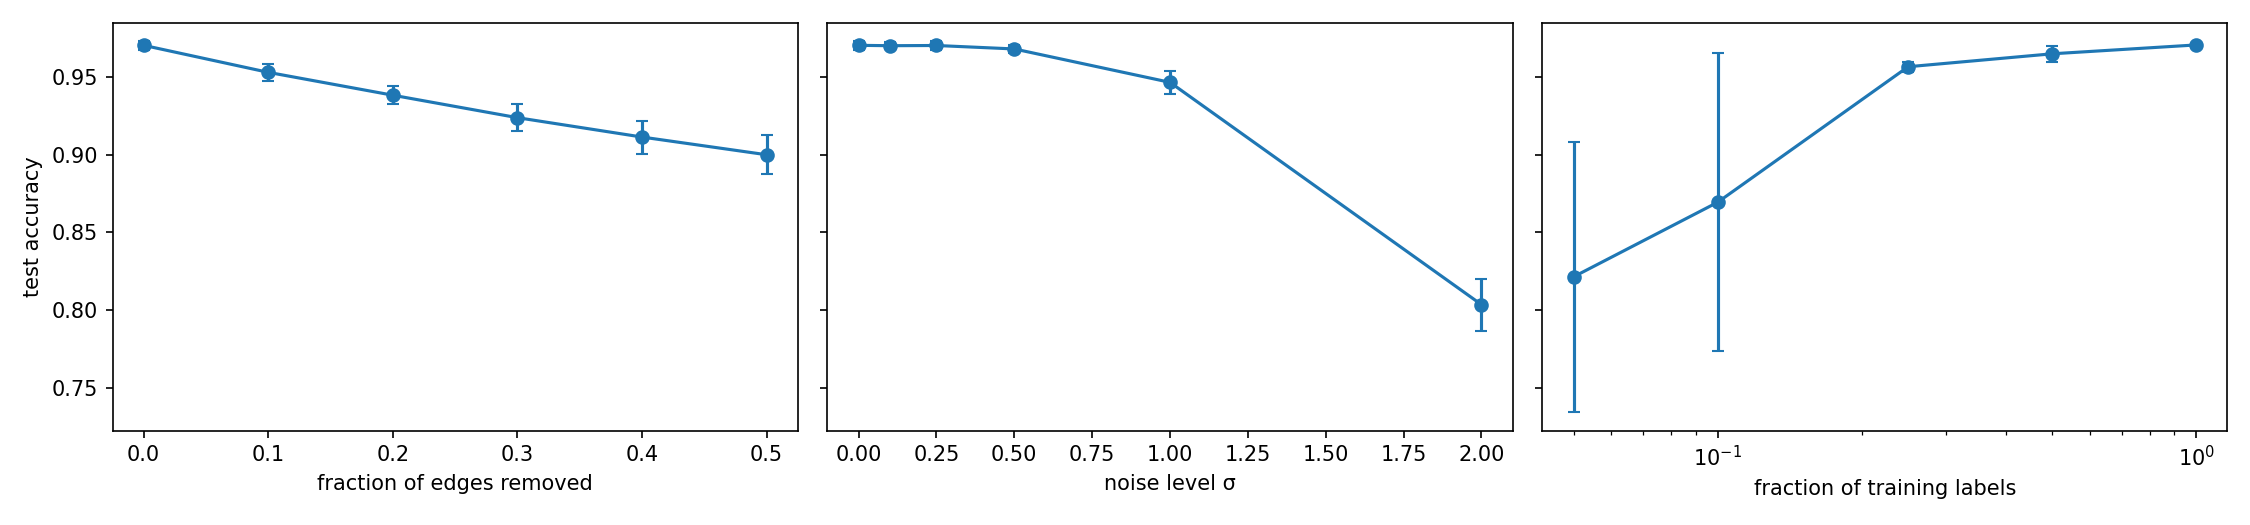

edge removal {0: np.float64(0.9702), 0.1: np.float64(0.9528), 0.2: np.float64(0.9381), 0.3: np.float64(0.9237), 0.4: np.float64(0.9112), 0.5: np.float64(0.8999)}
feature noise {0: np.float64(0.9702), 0.1: np.float64(0.9699), 0.25: np.float64(0.97), 0.5: np.float64(0.9678), 1: np.float64(0.9464), 2: np.float64(0.8036)}
label fraction {0.05: np.float64(0.8214), 0.1: np.float64(0.8693), 0.25: np.float64(0.9564), 0.5: np.float64(0.9647), 1.0: np.float64(0.9704)}


In [27]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, (d, lab) in zip(ax, [(drop, "fraction of edges removed"), (noise, "noise level σ"), (labels, "fraction of training labels")]):
    a.errorbar(list(d), [np.mean(v) for v in d.values()], [np.std(v) for v in d.values()], marker='o', capsize=3)
    a.set_xlabel(lab)
ax[2].set_xscale('log'); ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gcn_robustness.png', dpi=150); plt.show()
for name, d in [('edge removal', drop), ('feature noise', noise), ('label fraction', labels)]:
    print(name, {k: round(np.mean(v), 4) for k, v in d.items()})

## 28. Error analysis by cascade topology

The brief's examples are about nodes, such as accuracy by node degree. For graph classification we instead describe each cascade by its shape and ask whether the GCN fails more often on some shapes:

- **nodes**, the size $|V|$,
- **depth**, the longest path from the root to a leaf,
- **root degree**, how many users shared the news directly; the root is the hub of the cascade,
- **star share**, root degree divided by $|V|-1$: $1$ for a pure star, small for long chains.

Correctness of each test graph is averaged over the ten tuned runs, which smooths out seed noise.

In [28]:
import networkx as nx
from torch_geometric.utils import to_networkx

def shape(g):
    G = to_networkx(g, to_undirected=True)
    hops = nx.single_source_shortest_path_length(G, 0)
    return dict(nodes=g.num_nodes, depth=max(hops.values()), root_degree=G.degree(0), star_share=G.degree(0) / max(g.num_nodes - 1, 1))

T = pd.DataFrame([shape(g) for g in raw['test']])
T['y'] = y_test
C = (P > .5) == y_test
T['correct'] = C.mean(0)
print(T.groupby('y')[['nodes', 'depth', 'root_degree', 'star_share']].median())

   nodes  depth  root_degree  star_share
y                                       
0   69.5    2.0         58.0    0.925373
1   23.0    2.0         15.0    0.789474


## 29. Accuracy by quartile of each property

Each property is cut into quartiles over the test set, with fewer bins when many graphs share the same value. In every bin we compute accuracy for each of the ten runs and plot the mean with one standard deviation. The label under a bin gives the number of graphs in it.

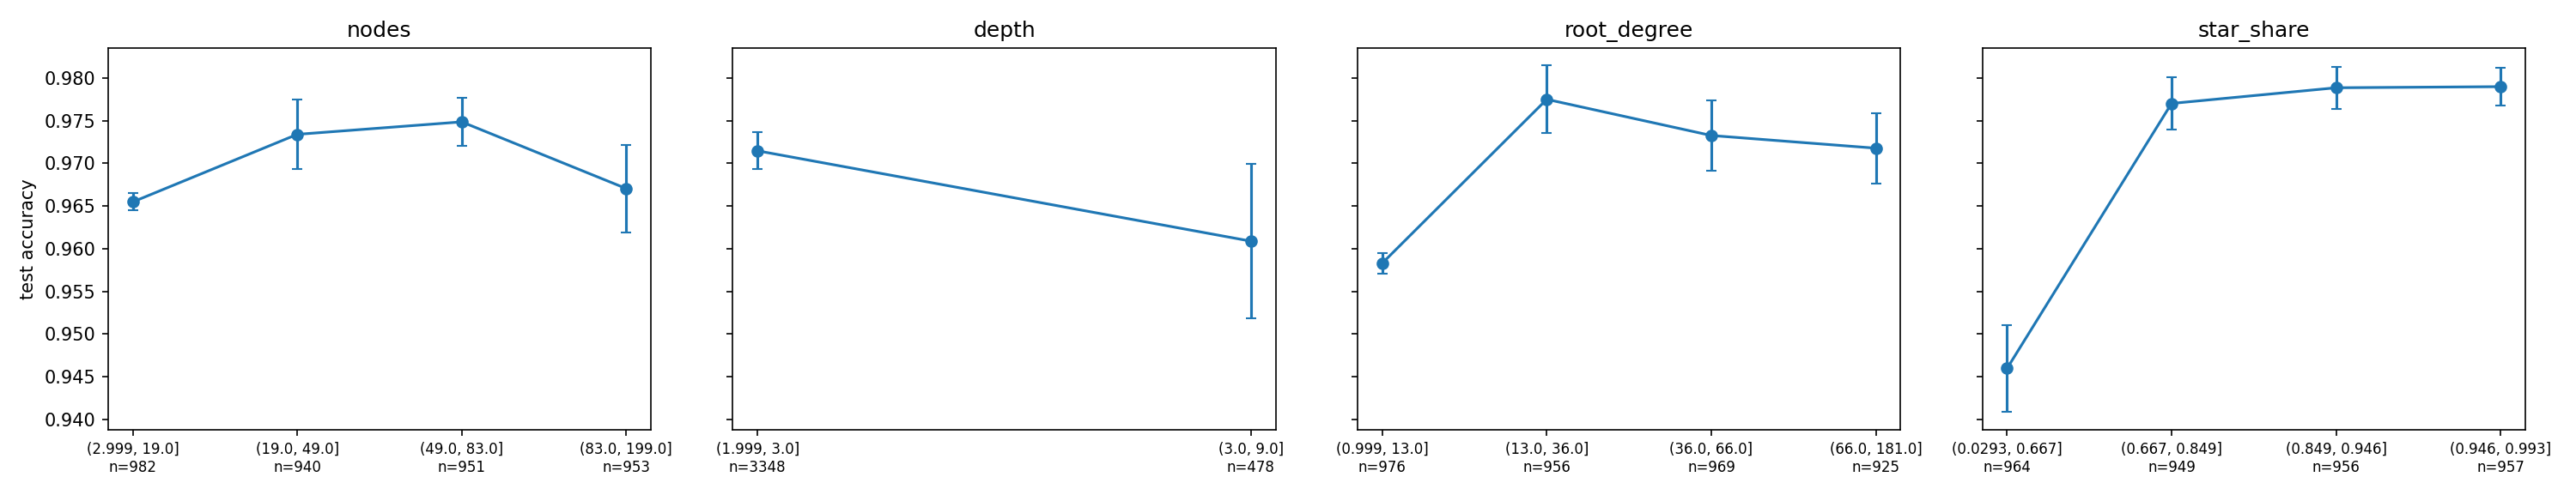

In [29]:
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for a, k in zip(ax, ['nodes', 'depth', 'root_degree', 'star_share']):
    q = pd.qcut(T[k], 4, duplicates='drop')
    acc = pd.DataFrame(C.T).groupby(q.values, observed=True).mean()
    a.errorbar(range(len(acc)), acc.mean(axis=1), acc.std(axis=1), marker='o', capsize=3)
    a.set_xticks(range(len(acc)), [f"{i}\nn={(q == i).sum()}" for i in acc.index], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gcn_topology.png', dpi=150); plt.show()

## 30. Shape or class?

A property can look linked to errors only because it differs between the two classes. Splitting the size quartiles by class separates the two effects.

We also count the graphs that every run gets wrong. These are the consistently hard cases, not seed noise.

In [30]:
q = pd.qcut(T.nodes, 4)
print(T.groupby([q, 'y'], observed=True).correct.agg(['mean', 'size']).unstack().round(3))
print("\nmisclassified by all ten runs:", (T.correct == 0).sum(), "   by none:", (T.correct == 1).sum(), "   of", len(T))

                mean        size     
y                  0      1    0    1
nodes                                
(2.999, 19.0]  0.684  0.999  104  878
(19.0, 49.0]   0.959  0.984  392  548
(49.0, 83.0]   0.986  0.940  721  230
(83.0, 199.0]  0.984  0.922  693  260

misclassified by all ten runs: 89    by none: 3678    of 3826


## 31. Explainability: masking feature groups

The simplest explanation method is occlusion: hide part of the input and see how far the model's confidence in its own prediction falls. On every test graph we

- zero the text block (columns 0 to 299) or the profile block (300 to 309) of every node,
- zero the news node's features only, or every user's features while keeping the news node,
- shuffle the users' feature rows across the batch, which keeps the feature distribution but breaks which user sits where.

We report test accuracy, the mean drop in confidence of the original prediction, and the share of predictions that flip.

In [31]:
def users(b):
    m = torch.ones(b.num_nodes, dtype=torch.bool, device=b.x.device); m[b.ptr[:-1]] = False
    return m

def zero_text(b):    b.x[:, :300] = 0
def zero_profile(b): b.x[:, 300:] = 0
def zero_news(b):    b.x[b.ptr[:-1]] = 0
def zero_users(b):   b.x[users(b)] = 0
def shuffle_users(b):
    u = users(b).nonzero().view(-1)
    b.x[u] = b.x[u[torch.randperm(len(u), device=u.device)]]

def occlude(f):
    bs = [b.clone() for b in test_b]
    for b in bs:
        f(b)
    p = predict(model, bs)
    c0 = np.where(p_best > .5, p_best, 1 - p_best)
    c1 = np.where(p_best > .5, p, 1 - p)
    return dict(acc=scores(y_test, p)['acc'], confidence_drop=(c0 - c1).mean(), flipped=((p > .5) != (p_best > .5)).mean())

torch.manual_seed(0)
occl = pd.DataFrame({name: occlude(f) for name, f in [('nothing', lambda b: None), ('text block', zero_text), ('profile block', zero_profile),
                     ('news node', zero_news), ('all users', zero_users), ('shuffle users', shuffle_users)]}).T
print(occl.round(4))

                  acc  confidence_drop  flipped
nothing        0.9723          -0.0000   0.0000
text block     0.5936           0.3286   0.4127
profile block  0.8479           0.1245   0.1312
news node      0.8905           0.2702   0.1006
all users      0.6934           0.2567   0.2946
shuffle users  0.7778           0.2216   0.2128


## 32. Explainability: four standard attribution methods

Occlusion tells us which feature groups matter on average. Attribution methods explain one graph at a time: they score every node feature and every edge by how much it pushed the model towards its prediction.

- **GNNExplainer** (Ying et al., 2019) learns a soft mask over edges and features that keeps the prediction while staying small.
- **PGExplainer** (Luo et al., 2020) trains one small network that predicts an edge mask from the two end-point embeddings, so it explains any graph without re-optimising. It scores edges only.
- **Saliency** is the absolute gradient of the predicted logit with respect to each input.
- **Integrated Gradients** (Sundararajan et al., 2017) integrates that gradient along a straight path from an all-zero input to the real one.

The last two come from Captum through PyG's `CaptumExplainer`. PGExplainer is first trained on 200 training graphs.

GNNExplainer works on its own copy of the model. It stores its edge mask as a parameter inside the GCN layers, and in PyG 2.8 that silently cuts the other methods' edge masks off from the gradient.

In [32]:
from torch_geometric.explain import Explainer, GNNExplainer, PGExplainer, CaptumExplainer
cfg = dict(mode='multiclass_classification', task_level='graph', return_type='raw')
model.eval()
explainers = {
    'GNNExplainer': Explainer(copy.deepcopy(model), GNNExplainer(epochs=200), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
    'PGExplainer': Explainer(model, PGExplainer(epochs=30, lr=0.003).to(device), 'phenomenon', cfg, edge_mask_type='object'),
    'Saliency': Explainer(model, CaptumExplainer('Saliency'), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
    'Integrated Gradients': Explainer(model, CaptumExplainer('IntegratedGradients'), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
}
random.seed(0)
pg_train = [g.clone().to(device) for g in random.sample(train_set, 200)]
for epoch in range(30):
    for g in pg_train:
        explainers['PGExplainer'].algorithm.train(epoch, model, g.x, g.edge_index, target=g.y)

## 33. Explain test graphs

We explain `n_explain` test graphs, half from each class. GNNExplainer, Saliency and Integrated Gradients explain the model's own prediction. PGExplainer, being a phenomenon explainer, explains the true label.

For every graph we keep the node-feature mask ($|V|\times310$) and the edge mask ($|E|$), and we time each method.

In [33]:
rng = np.random.RandomState(0)
idx = np.concatenate([rng.choice(np.where(y_test == c)[0], n_explain // 2, replace=False) for c in [0, 1]])
E, secs = {name: [] for name in explainers}, {name: 0.0 for name in explainers}
for i in idx:
    g = test_set[i].clone().to(device)
    for name, ex in explainers.items():
        t = time.time()
        e = ex(g.x, g.edge_index, target=g.y) if name == 'PGExplainer' else ex(g.x, g.edge_index)
        secs[name] += (time.time() - t) / len(idx)
        E[name].append((e.node_mask.detach().cpu() if 'node_mask' in e else None, e.edge_mask.detach().cpu()))
print({k: f"{v:.3f} s/graph" for k, v in secs.items()})

{'GNNExplainer': '2.083 s/graph', 'PGExplainer': '0.005 s/graph', 'Saliency': '0.013 s/graph', 'Integrated Gradients': '0.471 s/graph'}


## 34. Are the explanations faithful?

A faithful explanation points at inputs the model really uses. We test this with fidelity (Amara et al., 2022): remove the top $k$ fraction of nodes or edges by importance and measure how far the probability of the predicted class falls,

$\text{Fid}^+ = P(\hat y\mid G) - P(\hat y\mid G\setminus G_k)$

A node is removed by zeroing its features; an edge by deleting both of its directions. A method is only useful if it beats a random ranking, which we add as a baseline.

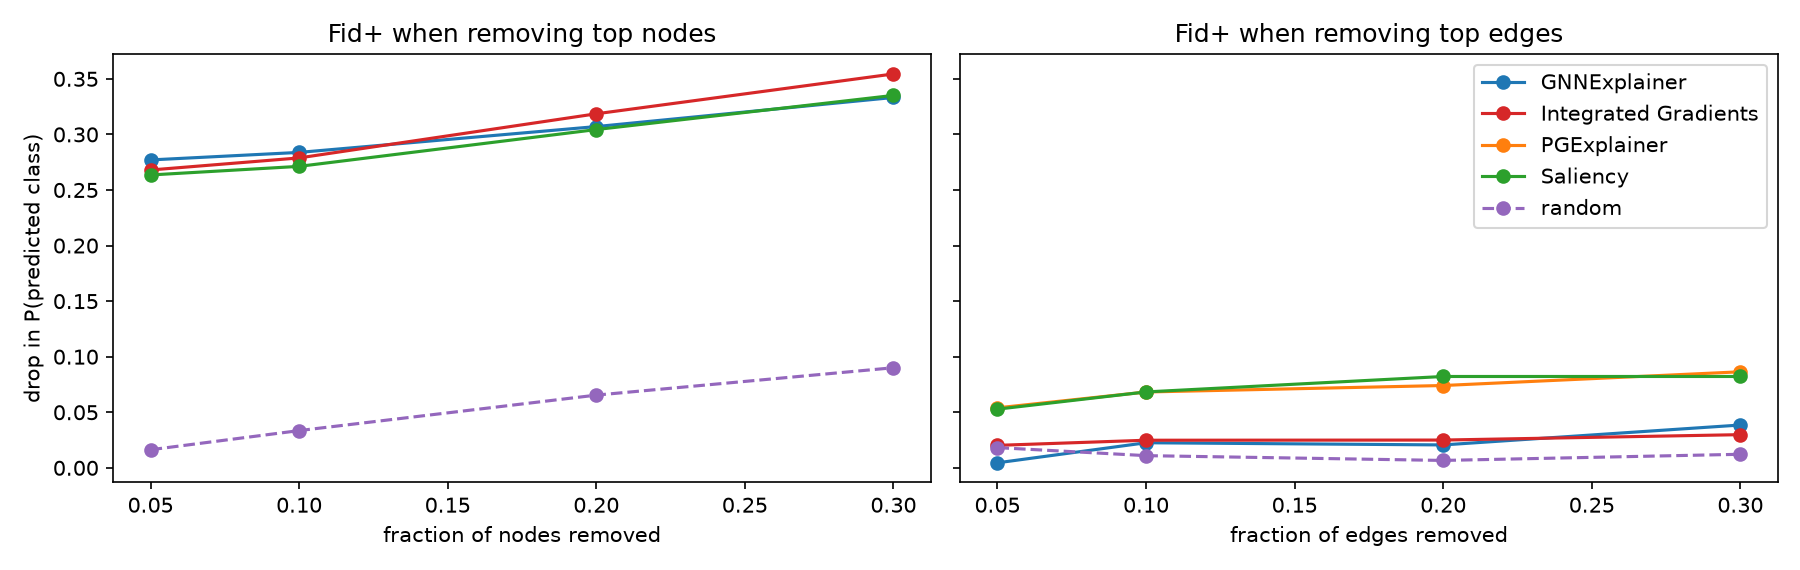

In [34]:
@torch.no_grad()
def conf(x, ei, c):
    return model(x, ei).softmax(1)[0, c].item()

def fid_nodes(g, score, k, c):
    x = g.x.clone()
    x[score.argsort(descending=True)[:max(1, int(k * g.num_nodes))]] = 0
    return conf(g.x, g.edge_index, c) - conf(x, g.edge_index, c)

def fid_edges(g, score, k, c):
    ei, w = to_undirected(g.edge_index, score, reduce='mean')
    pairs, w = ei[:, ei[0] < ei[1]], w[ei[0] < ei[1]]
    keep = torch.ones(pairs.size(1), dtype=torch.bool, device=pairs.device)
    keep[w.argsort(descending=True)[:max(1, int(k * pairs.size(1)))]] = False
    return conf(g.x, g.edge_index, c) - conf(g.x, to_undirected(pairs[:, keep]), c)

torch.manual_seed(0)
ks, rows = [.05, .1, .2, .3], []
for j, i in enumerate(idx):
    g, c = test_set[i].clone().to(device), int(p_best[i] > .5)
    for name in list(E) + ['random']:
        nm, em = E[name][j] if name != 'random' else (torch.rand(g.num_nodes, 1), torch.rand(g.num_edges))
        for k in ks:
            rows.append(dict(method=name, k=k, edges=fid_edges(g, em.to(device), k, c),
                             nodes=fid_nodes(g, nm.abs().sum(1).to(device), k, c) if nm is not None else np.nan))
fid = pd.DataFrame(rows).groupby(['method', 'k']).mean()
colors = dict(zip(list(E) + ['random'], plt.rcParams['axes.prop_cycle'].by_key()['color']))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, col in zip(ax, ['nodes', 'edges']):
    for name, d in fid[col].unstack('k').iterrows():
        if not d.isna().all():
            a.plot(ks, d.values, marker='o', label=name, color=colors[name], ls='--' if name == 'random' else '-')
    a.set_xlabel(f"fraction of {col} removed"); a.set_title(f"Fid+ when removing top {col}")
ax[0].set_ylabel("drop in P(predicted class)"); ax[1].legend()
plt.tight_layout(); plt.savefig('gcn_fidelity.png', dpi=150); plt.show()

## 35. What the explanations point at

Two summaries over the explained graphs, for the three methods that score node features:

- **Feature blocks.** The mean absolute attribution per column, in the text block and in the profile block. Taking a per-column mean makes the 300-column and the 10-column block comparable.
- **The news node.** The share of a graph's total node importance that lands on the root, against $1/|V|$, the share it would get if all nodes mattered equally.

In [35]:
rows = []
for name, ex in E.items():
    if ex[0][0] is None:
        continue
    M = torch.cat([nm.abs() for nm, _ in ex])
    share = [(nm.abs().sum(1)[0] / nm.abs().sum()).item() for nm, _ in ex if nm.abs().sum() > 0]
    rows.append(dict(method=name, text_per_column=M[:, :300].mean().item(), profile_per_column=M[:, 300:].mean().item(), news_node_share=np.mean(share)))
focus = pd.DataFrame(rows).set_index('method')
print(focus.round(4))
print("\nnews-node share if every node were equally important:", round(np.mean([1 / test_set[i].num_nodes for i in idx]), 4))

                      text_per_column  profile_per_column  news_node_share
method                                                                    
GNNExplainer                   0.2080              0.1152           0.4234
Saliency                       0.0078              0.0555           0.4999
Integrated Gradients           0.0024              0.0018           0.5222

news-node share if every node were equally important: 0.0365


## 36. Two explained cascades

From each class we draw the correctly classified explained cascade whose size is closest to 40 nodes. The news node is the large square. Node colour is the Integrated Gradients importance of the node, and edge width is GNNExplainer's edge importance.

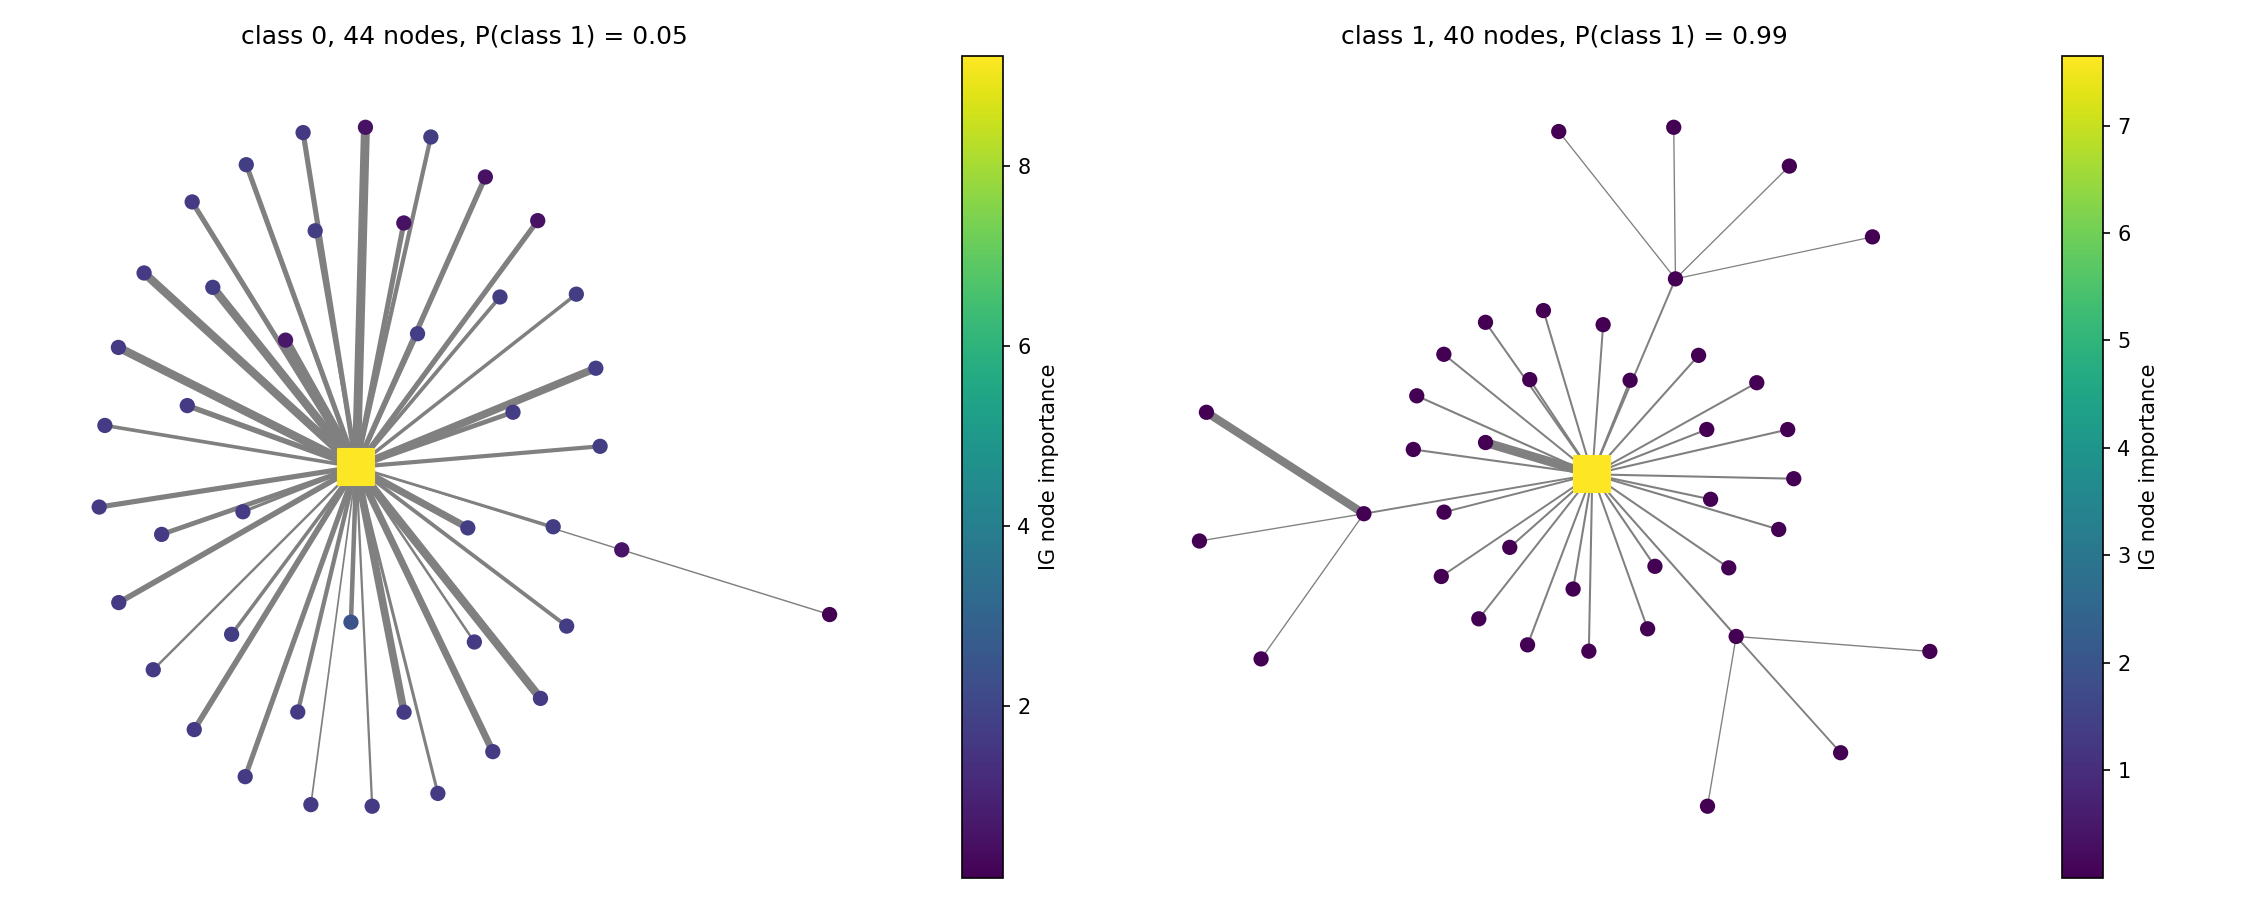

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, c in zip(ax, [0, 1]):
    j = min((j for j, i in enumerate(idx) if y_test[i] == c and (p_best[i] > .5) == c), key=lambda j: abs(test_set[idx[j]].num_nodes - 40))
    i = idx[j]
    G = to_networkx(raw['test'][i], to_undirected=True)
    node = E['Integrated Gradients'][j][0].abs().sum(1).numpy()
    ei, w = to_undirected(test_set[i].edge_index.cpu(), E['GNNExplainer'][j][1], reduce='mean')
    w = {tuple(e): v for e, v in zip(ei.t().tolist(), (w / w.max()).tolist())}
    pos = nx.kamada_kawai_layout(G)
    kw = dict(ax=a, cmap='viridis', vmin=node.min(), vmax=node.max())
    nx.draw_networkx_edges(G, pos, ax=a, width=[0.3 + 4 * w[tuple(sorted(e))] for e in G.edges()], edge_color='grey')
    pc = nx.draw_networkx_nodes(G, pos, nodelist=list(range(1, len(node))), node_color=node[1:], node_size=40, **kw)
    nx.draw_networkx_nodes(G, pos, nodelist=[0], node_color=node[:1], node_size=300, node_shape='s', **kw)
    fig.colorbar(pc, ax=a, label="IG node importance")
    a.set_title(f"class {c}, {len(node)} nodes, P(class 1) = {p_best[i]:.2f}"); a.axis('off')
plt.tight_layout(); plt.savefig('gcn_explained_cascades.png', dpi=150); plt.show()

## 37. Save the results

Everything needed to compare the GCN with the other two models goes into one JSON file. The per-run test probabilities are saved too, so the three models' errors can later be compared graph by graph.

In [37]:
import json
res = dict(model='GCN', dataset='UPFD gossipcop, content features', best_config=best,
           baseline=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(), tuned_runs=tuned.to_dict('list'),
           ablation_input=table(abl).to_dict('index'), ablation_model=table(arch).to_dict('index'),
           depth={f'root={r}, layers={L}': [v.acc.mean(), v.acc.std()] for (r, L), v in depth.items()},
           efficiency=eff, size_sweep=sizes.to_dict('records'),
           edge_removal={str(k): v for k, v in drop.items()}, feature_noise={str(k): v for k, v in noise.items()},
           label_fraction={str(k): v for k, v in labels.items()},
           occlusion=occl.to_dict('index'), fidelity={f'{m}, k={k}': v for (m, k), v in fid.to_dict('index').items()},
           explanation_focus=focus.to_dict('index'), explainer_seconds_per_graph=secs)
json.dump(res, open('gcn_upfd_results.json', 'w'), indent=1, default=float)
np.save('gcn_upfd_test_probs.npy', P)
search.to_csv('gcn_upfd_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))

saved: ablation_input, ablation_model, baseline, best_config, dataset, depth, edge_removal, efficiency, explainer_seconds_per_graph, explanation_focus, feature_noise, fidelity, label_fraction, model, occlusion, size_sweep, tuned, tuned_runs


## 38. Conclusion

The whole notebook ran in 86 minutes on a Kaggle T4.

**Milestone 2.** Cascade size alone gives 0.752 test accuracy. The textbook GCN reaches 0.947 ± 0.005 and the tuned GCN 0.970 ± 0.003 over ten fresh seeds, with macro-F1 0.970 and ROC-AUC 0.988. The chosen configuration has 4 layers of width 32, max readout, the root shortcut, dropout 0.2, no batch norm, learning rate $3\cdot10^{-3}$, weight decay $10^{-5}$ and batch size 64. The top three configurations lie within one standard deviation of each other on validation, so the choice among them is not significant.

**What the GCN uses.**

- The node features carry almost everything. With constant features the GCN falls to 0.744, roughly what size alone gives. Without edges ($\tilde A=I$) it loses only 0.003, within seed noise, and a random tree loses 0.005. On Gossipcop the GCN works mainly as a learned pooling of user and news features; who-retweeted-whom adds little.
- If edges are used they must be undirected: parent $\rightarrow$ child edges (0.947) are worse than no edges at all.
- The text block matters more than the profile block: text only gives 0.957, profile only 0.915, and zeroing the text block at test time drops accuracy to 0.594.
- The news node alone gives 0.948, as much as the textbook GCN. The users add about two points, and so does the root shortcut (0.946 without it).
- Max readout beats mean (−0.012) and sum (−0.020).

**Depth.** Without the root shortcut, 2 and 4 layers are best (0.969 and 0.970) and 8 layers become unstable (0.919 ± 0.092): some seeds collapse, as over-smoothing predicts. With the shortcut, 8 layers still reach 0.969, because the classifier can fall back on the news features.

**Visualisation.** The silhouette score rises from 0.149 for the mean raw features to 0.595 for the GCN embedding. The misclassified graphs sit where the two classes meet or inside the other class.

**Efficiency.** The tuned GCN has 25k parameters, trains at 0.22 s per epoch with 16 MB of peak GPU memory, and scores all 3,826 test graphs in 0.05 s (4 ms for a single graph, mostly overhead). Widths above 64 add parameters but no accuracy, and the epoch time hardly changes between 11k and 1.6M parameters, so training is limited by batching rather than arithmetic.

**Robustness.** Removing half of the edges at test time costs 7 points (0.900), even though a model trained without edges loses almost nothing: a model trained with edges expects them. Feature noise up to $\sigma=0.5$ is harmless, and $\sigma=2$ costs 17 points. With 5% of the training labels (54 graphs) accuracy is still 0.821, and with 25% it is within 1.5 points of the full set.

**Topology.** Errors concentrate on cascades whose size is atypical for their class: small class-0 cascades (at most 19 nodes, accuracy 0.684) and large class-1 cascades (more than 83 nodes, 0.922). Chain-like cascades, with a star share below 0.67, are the hardest shape (0.946). 89 test graphs are misclassified by all ten runs.

**Explainability.** The three node-level methods are faithful: removing the top 5% of nodes lowers the probability of the predicted class by 0.26 to 0.28, against 0.02 for random nodes. Most of that comes from the news node, which receives 42% to 52% of the total importance against a uniform share of 3.7%. Edge explanations are weak for every method (at most 0.09), which agrees with the edge ablations: the GCN does not depend on particular edges. Among the node-level methods Saliency is the cheapest at 0.013 s per graph; GNNExplainer needs 2.1 s.